# Exploratory data analysis

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/cleaned/books_cleaned.csv")

df.head()

,title,category,book_url,image_url,description,image_path,title_length,description_length
0,Soumission,Fiction,https://books.toscrape.com/catalogue/soumissio...,https://books.toscrape.com/media/cache/3e/ef/3...,"Dans une France assez proche de la nôtre, un h...",images/book_0.jpg,10,1093
1,Private Paris (Private #10),Fiction,https://books.toscrape.com/catalogue/private-p...,https://books.toscrape.com/media/cache/9d/05/9...,Paris is burning--and only Private's Jack Morg...,images/book_1.jpg,27,1131
2,"We Love You, Charlie Freeman",Fiction,https://books.toscrape.com/catalogue/we-love-y...,https://books.toscrape.com/media/cache/5f/15/5...,"The Freeman family--Charles, Laurel, and their...",images/book_2.jpg,28,1491
3,Thirst,Fiction,https://books.toscrape.com/catalogue/thirst_94...,https://books.toscrape.com/media/cache/c4/0a/c...,"On a searing summer Friday, Eddie Chapman has ...",images/book_3.jpg,6,1451
4,The Murder That Never Was (Forensic Instincts #5),Fiction,https://books.toscrape.com/catalogue/the-murde...,https://books.toscrape.com/media/cache/dc/44/d...,"Given the opportunity, would you assume someon...",images/book_4.jpg,49,1843


### Books Category Analysis

In [ ]:
print(df["category"].value_counts())

print("\nPercentage of books category:")
print((df["category"].value_counts(normalize=True) * 100).round(1))

category
Nonfiction    110
Fiction        65
Name: count, dtype: int64

Percentage of books category:
category
Nonfiction    62.9
Fiction       37.1
Name: proportion, dtype: float64


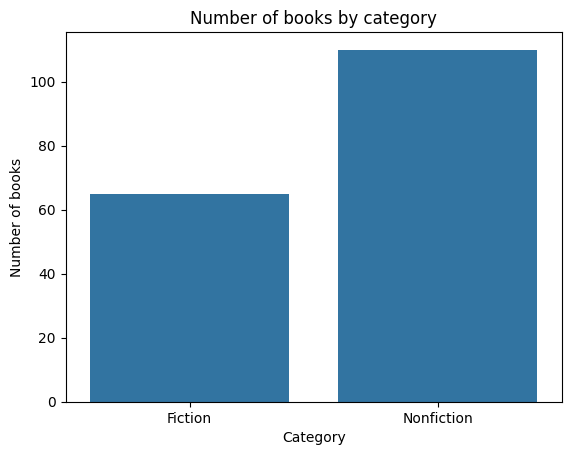

In [16]:
sns.countplot( x="category", data=df, order=["Fiction", "Nonfiction"])

plt.title("Number of books by category")
plt.xlabel("Category")
plt.ylabel("Number of books")

plt.show()

### Books Tittle Analysis


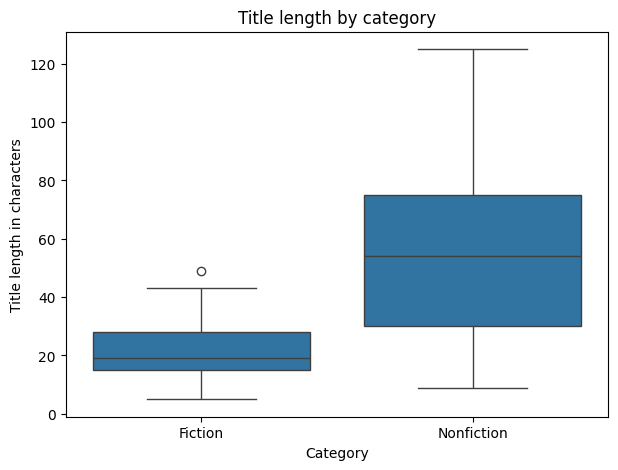

In [17]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x="category",
    y="title_length",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Title length by category")
plt.xlabel("Category")
plt.ylabel("Title length in characters")

plt.show()

Text(0, 0.5, 'Density')

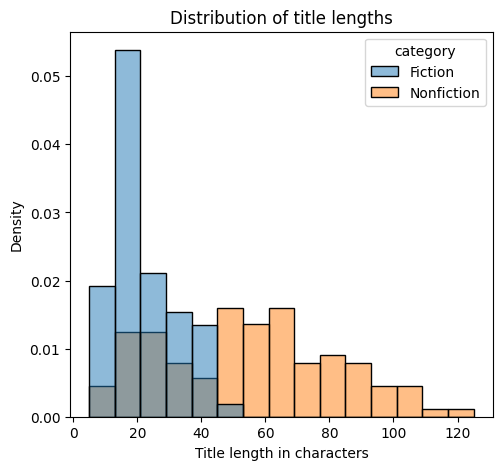

In [22]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.histplot(
    data=df,
    x="title_length",
    hue="category",
    bins=15,
    stat="density",
    common_norm=False
)

plt.title("Distribution of title lengths")
plt.xlabel("Title length in characters")
plt.ylabel("Density")



### Book Description Analysis


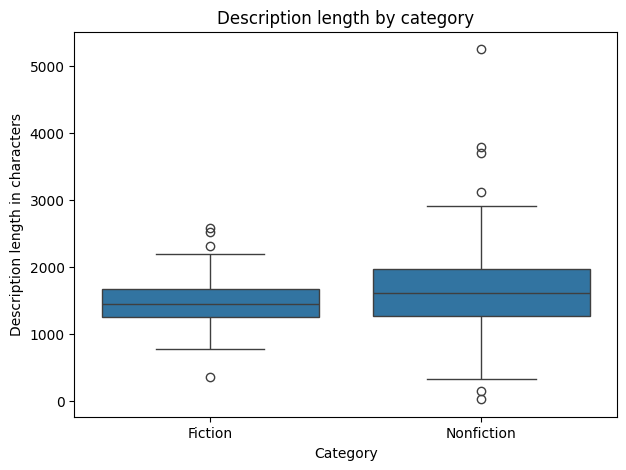

In [18]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    x="category",
    y="description_length",
    data=df,
    order=["Fiction", "Nonfiction"]
)

plt.title("Description length by category")
plt.xlabel("Category")
plt.ylabel("Description length in characters")

plt.show()

In [19]:
df.groupby("category")[
    ["title_length", "description_length"]
].describe()

title_length                                                      \
                  count       mean        std  min   25%   50%   75%    max   
category                                                                      
Fiction            65.0  21.569231  10.190328  5.0  15.0  19.0  28.0   49.0   
Nonfiction        110.0  54.390909  27.662479  9.0  30.0  54.0  75.0  125.0   

           description_length                                           \
                        count         mean         std    min      25%   
category                                                                 
Fiction                  65.0  1465.030769  394.860615  364.0  1251.00   
Nonfiction              110.0  1675.854545  697.197297   30.0  1276.25   

                                    
               50%     75%     max  
category                            
Fiction     1451.0  1669.0  2584.0  
Nonfiction  1617.5  1972.5  5254.0

In [20]:
columns = [
    "title",
    "category",
    "description_length",
    "book_url"
]

sorted_books = df.sort_values("description_length")

print("Shortest descriptions:")
display(sorted_books[columns].head(5))

print("Longest descriptions:")
display(sorted_books[columns].tail(5))

Shortest descriptions:


,title,category,description_length,book_url
169,Kindle Paperwhite User's Guide,Nonfiction,30,https://books.toscrape.com/catalogue/kindle-pa...
118,Smarter Faster Better: The Secrets of Being Pr...,Nonfiction,155,https://books.toscrape.com/catalogue/smarter-f...
136,"Data, A Love Story: How I Gamed Online Dating ...",Nonfiction,326,https://books.toscrape.com/catalogue/data-a-lo...
36,The Bourne Identity (Jason Bourne #1),Fiction,364,https://books.toscrape.com/catalogue/the-bourn...
44,Siddhartha,Fiction,785,https://books.toscrape.com/catalogue/siddharth...


Longest descriptions:


,title,category,description_length,book_url
82,The Genius of Birds,Nonfiction,2919,https://books.toscrape.com/catalogue/the-geniu...
87,Becoming Wise: An Inquiry into the Mystery and...,Nonfiction,3128,https://books.toscrape.com/catalogue/becoming-...
81,The Omnivore's Dilemma: A Natural History of F...,Nonfiction,3707,https://books.toscrape.com/catalogue/the-omniv...
146,The Name of God is Mercy,Nonfiction,3791,https://books.toscrape.com/catalogue/the-name-...
101,Buying In: The Secret Dialogue Between What We...,Nonfiction,5254,https://books.toscrape.com/catalogue/buying-in...


In [21]:
shortest_book = sorted_books.iloc[0]
longest_book = sorted_books.iloc[-1]

print("SHORTEST DESCRIPTION")
print("Title:", shortest_book["title"])
print("URL:", shortest_book["book_url"])
print(shortest_book["description"])

print("\nLONGEST DESCRIPTION")
print("Title:", longest_book["title"])
print("URL:", longest_book["book_url"])
print(longest_book["description"])

SHORTEST DESCRIPTION
Title: Kindle Paperwhite User's Guide
URL: https://books.toscrape.com/catalogue/kindle-paperwhite-users-guide_103/index.html
Kindle Paperwhite User's Guide

LONGEST DESCRIPTION
Title: Buying In: The Secret Dialogue Between What We Buy and Who We Are
URL: https://books.toscrape.com/catalogue/buying-in-the-secret-dialogue-between-what-we-buy-and-who-we-are_670/index.html
“Fascinating … A compelling blend of cultural anthropology and business journalism.” — Andrea Sachs, Time Magazine “An often startling tour of new cultural terrain.” — Laura Miller, Salon “Marked by meticulous research and careful conclusions, this superbly readable book confirms New York Times journalist Walker as an expert on consumerism. … [A] thoughtful and unhurried i “Fascinating … A compelling blend of cultural anthropology and business journalism.” — Andrea Sachs, Time Magazine “An often startling tour of new cultural terrain.” — Laura Miller, Salon “Marked by meticulous research and careful 

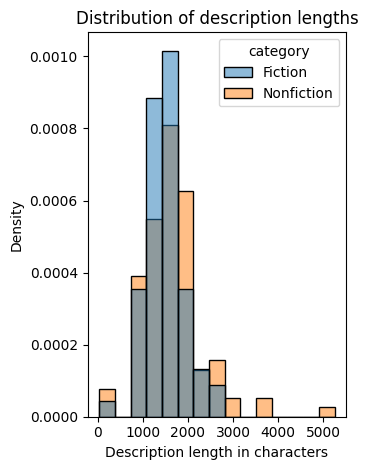

In [23]:
plt.subplot(1, 2, 2)

sns.histplot(
    data=df,
    x="description_length",
    hue="category",
    bins=15,
    stat="density",
    common_norm=False
)

plt.title("Distribution of description lengths")
plt.xlabel("Description length in characters")
plt.ylabel("Density")

plt.tight_layout()
plt.show()